# PhisGuard: URL Threat Detection Engine
Notebook Eksperimen dan Pipeline Deteksi URL Phishing

---

### Informasi Proyek dan Roadmap Model
* Domain: Cybersecurity / Phishing URL Detection
* Target Model (Production): XGBoost Classifier
* Baseline Model: Random Forest Classifier
* Nama Dataset: LegitPhish Dataset
* Sumber Dataset: Mendeley Data (DOI: [10.17632/hx4m73v2sf.2](https://data.mendeley.com/datasets/hx4m73v2sf/2))
* Penulis: Rachana Potpelwar, Uday Kulkarni, Jaishri Waghmare (2025)
* Sumber Koleksi:
  * Phishing URLs: URLHaus dan PhishTank (feed intelijen ancaman terverifikasi)
  * Legitimate URLs: Google Search API, Wikipedia, dan Stack Overflow

---
### Struktur Notebook
1. CHAPTER 1 : Dataset Quality Audit
2. CHAPTER 2 : Data Cleaning & Preprocessing
3. CHAPTER 3 : Model Training & Evaluation (Tahap Selanjutnya)


# CHAPTER 1 : Dataset Quality Audit

Bab ini berfokus pada audit komprehensif kualitas data mentah LegitPhish:
1. Integritas skema, tipe data, missing values, dan nilai sentinel.
2. Identifikasi artefak data kotor dan duplikasi baris.
3. Distribusi kelas dan verifikasi polaritas label target.
4. Profiling statistik tendensi sentral (Mean vs Median), IQR, dan skewness.
5. Uji hipotesis statistik (Mann-Whitney U Test) dan peringkat Effect Size (Cohen's d).
6. Analisis multikolinearitas dan korelasi antar fitur.
7. Evaluasi risiko bias sumber data (HTTPS flag dan domain authority).


## 1.1 Problem Framing & Decision Canvas (/data-question-framing)

* Unit of Analysis: Satu baris URL tunggal beserta 16 fitur leksikal numerik yang diekstrak.
* Target Definition: Kolom ClassLabel.
  * Catatan Polarisasi Label Mentah: Pada dataset LegitPhish, nilai 0.0 mewakili Phishing dan 1.0 mewakili Legitimate.
* Baseline vs Candidate Model:
  * Baseline: Random Forest Classifier.
  * Kandidat Produksi: XGBoost Classifier.
* Guardrail Metric: False Positive Rate (FPR) pada URL legitimate harus ditekan seminimal mungkin agar tidak mengganggu akses pengguna ke situs sah, sementara Recall pada kelas Phishing harus dioptimalkan.


## 1.2 Data Ingestion & Structural Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set visual styling tanpa emotikon
sns.set_theme(style='whitegrid', font='sans-serif')
palette = {'Phishing (0)': '#e74c3c', 'Legitimate (1)': '#2ecc71'}

DATA_PATH = Path('data/url/url_features_extracted1.csv')
PLOT_DIR = Path('plots/url')
PLOT_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(DATA_PATH)
print("Dataset URL mentah berhasil dimuat.")
print(f"Dimensi Data: {df_raw.shape[0]:,} baris, {df_raw.shape[1]} kolom.")
df_raw.head(3)


Dataset URL mentah berhasil dimuat.
Dimensi Data: 101,219 baris, 18 kolom.


,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.250669,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196439,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936180,5,0,1,2,1,0,0,0,0,12,0.0,0.0


## 1.3 Schema & Data Type Verification

In [2]:
schema_info = pd.DataFrame({
    'Column': df_raw.columns,
    'Non-Null Count': df_raw.notnull().sum().values,
    'Null Count': df_raw.isnull().sum().values,
    'Dtype': df_raw.dtypes.values
})
print("Ringkasan Skema Kolom:")
display(schema_info)

mem_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Estimasi Penggunaan Memori: {mem_mb:.2f} MB")


Ringkasan Skema Kolom:


,Column,Non-Null Count,Null Count,Dtype
0,URL,101219,0,str
1,url_length,101219,0,int64
2,has_ip_address,101219,0,int64
3,dot_count,101219,0,int64
4,https_flag,101219,0,int64
5,url_entropy,101219,0,float64
6,token_count,101219,0,int64
7,subdomain_count,101219,0,int64
8,query_param_count,101219,0,int64
9,tld_length,101219,0,int64


Estimasi Penggunaan Memori: 17.28 MB


## 1.4 Missing Values & Data Corruption Anomaly Audit

Pemeriksaan keberadaan missing value (NaN), nilai sentinel, dan artefak crawler.


In [3]:
null_series = df_raw.isnull().sum()
null_cols = null_series[null_series > 0]
print("Audit Missing Values:")
if len(null_cols) == 0:
    print("Tidak ada missing value.")
else:
    for col, val in null_cols.items():
        print(f"- Kolom '{col}': {val} missing value ({val/len(df_raw)*100:.4f}%)")

null_row = df_raw[df_raw['ClassLabel'].isnull()]
print("\nBaris dengan ClassLabel NaN:")
display(null_row[['URL', 'url_length', 'ClassLabel']])

negative_subdomains = (df_raw['subdomain_count'] < 0).sum()
print(f"\nJumlah baris dengan subdomain_count < 0 (nilai sentinel -1): {negative_subdomains:,} baris")

status_artifacts = df_raw[df_raw['URL'].str.lower().isin(['offline', 'online', 'error', '404', 'nan'])]
print(f"Jumlah artefak status crawler pada kolom URL: {len(status_artifacts)}")
display(status_artifacts[['URL', 'url_length', 'subdomain_count', 'ClassLabel']])


Audit Missing Values:


- Kolom 'ClassLabel': 1 missing value (0.0010%)

Baris dengan ClassLabel NaN:


,URL,url_length,ClassLabel
65118,https://www.chocolatleroux.com,30,NaN



Jumlah baris dengan subdomain_count < 0 (nilai sentinel -1): 1,308 baris
Jumlah artefak status crawler pada kolom URL: 1


,URL,url_length,subdomain_count,ClassLabel
599,Offline,7,-1,0.0


## 1.5 Deduplication & Integrity Audit

In [4]:
exact_duplicates = df_raw.duplicated().sum()
print(f"Duplikasi Baris Persis (Identik di semua kolom): {exact_duplicates:,}")

url_duplicates = df_raw['URL'].duplicated().sum()
print(f"Duplikasi pada Kolom URL: {url_duplicates:,}")

url_label_conflict = df_raw.groupby('URL')['ClassLabel'].nunique()
conflicting_urls = url_label_conflict[url_label_conflict > 1]
print(f"Jumlah URL dengan Label Bertentangan: {len(conflicting_urls)}")

# Subset bersih sementara untuk analisis statistik audit
df_audit = df_raw.dropna(subset=['ClassLabel']).copy()
df_audit['ClassLabel'] = df_audit['ClassLabel'].astype(int)
df_audit['Class_Name'] = df_audit['ClassLabel'].map({0: 'Phishing (0)', 1: 'Legitimate (1)'})


Duplikasi Baris Persis (Identik di semua kolom): 346
Duplikasi pada Kolom URL: 346


Jumlah URL dengan Label Bertentangan: 0


## 1.6 Class Distribution & Imbalance Audit

Distribusi Kelas Target:
- Phishing (0): 63,678 sampel (62.91%)
- Legitimate (1): 37,540 sampel (37.09%)
Rasio Ketidakseimbangan (Phishing : Legitimate): 1.70 : 1


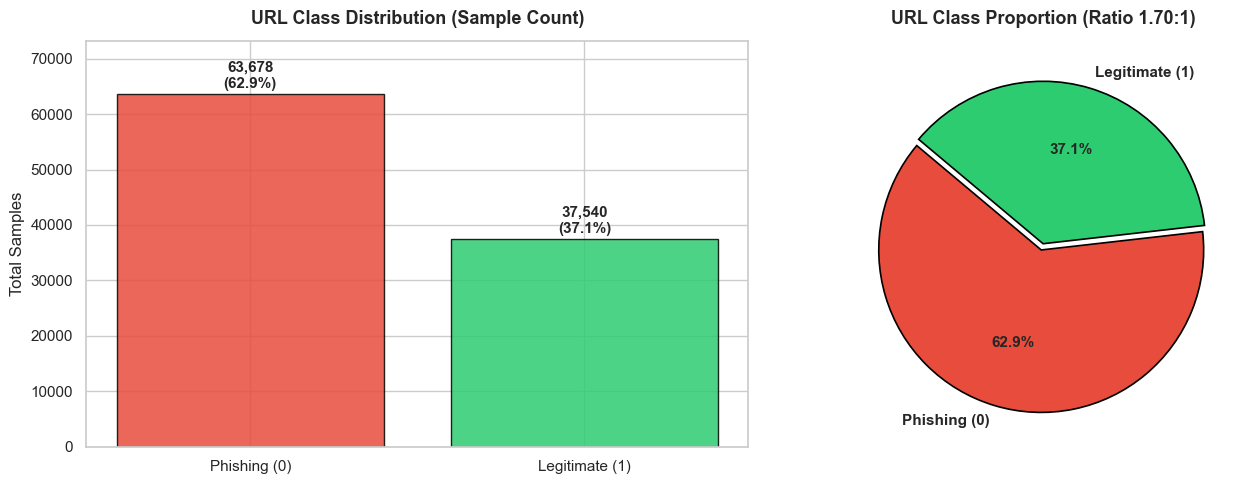

Plot disimpan di: plots\url\01_url_class_distribution.png


In [5]:
class_counts = df_audit['Class_Name'].value_counts()
class_pcts = df_audit['Class_Name'].value_counts(normalize=True) * 100
imbalance_ratio = class_counts['Phishing (0)'] / class_counts['Legitimate (1)']

print("Distribusi Kelas Target:")
for cname in class_counts.index:
    print(f"- {cname}: {class_counts[cname]:,} sampel ({class_pcts[cname]:.2f}%)")
print(f"Rasio Ketidakseimbangan (Phishing : Legitimate): {imbalance_ratio:.2f} : 1")

# Visualisasi Distribusi Kelas
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(class_counts.index, class_counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black', alpha=0.85)
for i, v in enumerate(class_counts.values):
    pct = v / len(df_audit) * 100
    ax[0].text(i, v + 1000, f'{v:,}\n({pct:.1f}%)', ha='center', fontweight='bold', fontsize=11)
ax[0].set_title('URL Class Distribution (Sample Count)', fontsize=13, fontweight='bold', pad=12)
ax[0].set_ylabel('Total Samples')
ax[0].set_ylim(0, max(class_counts.values) * 1.15)

ax[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%', colors=['#e74c3c', '#2ecc71'],
          startangle=140, explode=(0.04, 0), wedgeprops={'edgecolor': 'black', 'linewidth': 1.2},
          textprops={'fontsize': 11, 'fontweight': 'bold'})
ax[1].set_title(f'URL Class Proportion (Ratio {imbalance_ratio:.2f}:1)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plot_file1 = PLOT_DIR / '01_url_class_distribution.png'
plt.savefig(plot_file1, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {plot_file1}")


## 1.7 Statistical Profiling & Central Tendency (/statistical-analysis)

In [6]:
num_cols = df_audit.select_dtypes(include=[np.number]).columns.drop('ClassLabel').tolist()

stat_summary = []
for col in num_cols:
    s = df_audit[col]
    mean_val = s.mean()
    median_val = s.median()
    iqr_val = s.quantile(0.75) - s.quantile(0.25)
    skew_val = s.skew()
    stat_summary.append({
        'Feature': col,
        'Mean': round(mean_val, 2),
        'Median': round(median_val, 2),
        'Std': round(s.std(), 2),
        'IQR': round(iqr_val, 2),
        'Skewness': round(skew_val, 2),
        'Min': round(s.min(), 2),
        'p1': round(s.quantile(0.01), 2),
        'p25': round(s.quantile(0.25), 2),
        'p50': round(median_val, 2),
        'p75': round(s.quantile(0.75), 2),
        'p99': round(s.quantile(0.99), 2),
        'Max': round(s.max(), 2)
    })

stat_df = pd.DataFrame(stat_summary)
print("Ringkasan Statistik 16 Fitur Numerik:")
display(stat_df)


Ringkasan Statistik 16 Fitur Numerik:


,Feature,Mean,Median,Std,IQR,Skewness,Min,p1,p25,p50,p75,p99,Max
0,url_length,35.06,31.00,16.81,8.00,5.83,7.00,19.00,27.00,31.00,35.00,87.83,474.00
1,has_ip_address,0.48,0.00,0.50,1.00,0.06,0.00,0.00,0.00,0.00,1.00,1.00,1.00
2,dot_count,3.01,3.00,0.95,2.00,1.40,0.00,2.00,2.00,3.00,4.00,5.00,19.00
3,https_flag,0.41,0.00,0.49,1.00,0.38,0.00,0.00,0.00,0.00,1.00,1.00,1.00
4,url_entropy,3.98,3.94,0.31,0.33,0.86,2.52,3.42,3.77,3.94,4.10,4.80,5.87
5,token_count,6.89,7.00,1.67,3.00,2.24,1.00,5.00,5.00,7.00,8.00,11.00,48.00
6,subdomain_count,1.51,2.00,0.62,1.00,-1.04,-1.00,-1.00,1.00,2.00,2.00,2.00,5.00
7,query_param_count,1.01,1.00,0.20,0.00,33.43,1.00,1.00,1.00,1.00,1.00,1.00,14.00
8,tld_length,5.00,3.00,2.92,5.00,0.34,0.00,0.00,3.00,3.00,8.00,9.00,10.00
9,path_length,8.54,2.00,14.70,7.00,4.77,0.00,0.00,0.00,2.00,7.00,60.00,317.00


## 1.8 Bivariate Hypothesis Testing & Feature Discriminative Power

Hasil Uji Hipotesis Mann-Whitney U dan Effect Size Cohen's d:


,Feature,Phish_Mean,Phish_Median,Legit_Mean,Legit_Median,Cohen_d,p_value
3,https_flag,0.055,0.000,1.000,1.00,-5.205,0.000000e+00
15,percentage_numeric_chars,38.220,45.455,0.248,0.00,2.918,0.000000e+00
5,token_count,7.882,8.000,5.196,5.00,2.555,0.000000e+00
11,number_of_digits,13.477,15.000,0.081,0.00,2.403,0.000000e+00
1,has_ip_address,0.771,1.000,0.000,0.00,2.312,0.000000e+00
2,dot_count,3.510,4.000,2.155,2.00,1.981,0.000000e+00
8,tld_length,6.345,8.000,2.727,3.00,1.549,0.000000e+00
12,tld_popularity,0.115,0.000,0.691,1.00,-1.523,0.000000e+00
14,domain_name_length,4.114,3.000,9.986,10.00,-1.297,0.000000e+00
6,subdomain_count,1.722,2.000,1.155,1.00,1.009,0.000000e+00


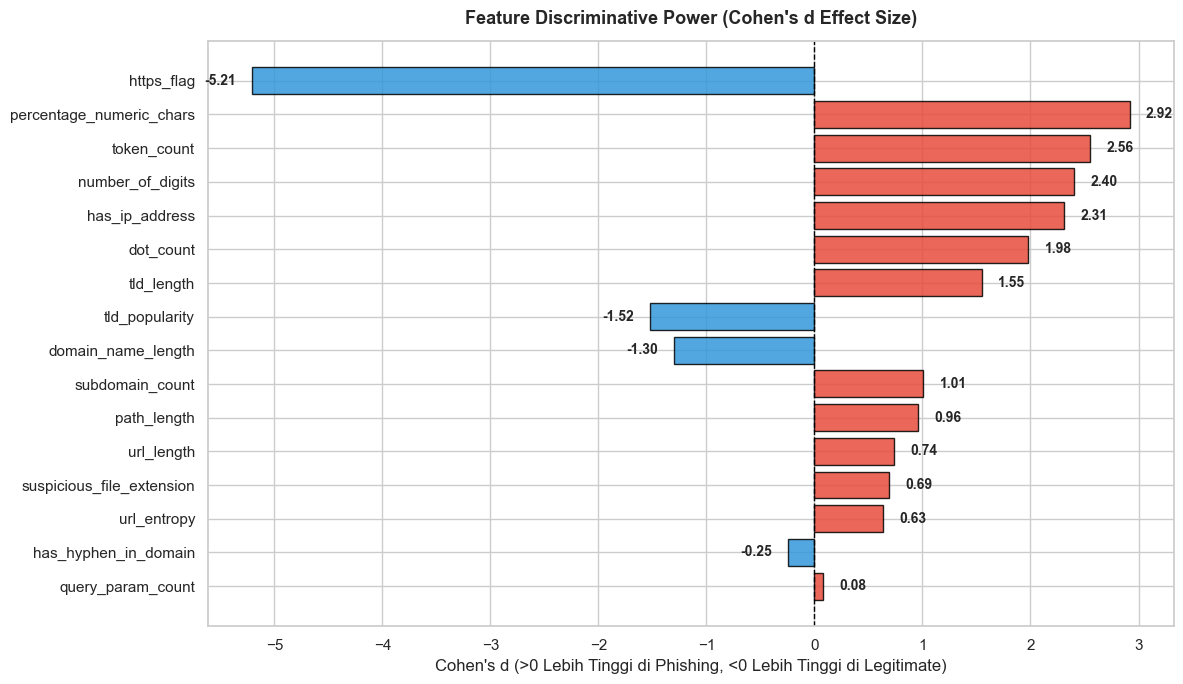

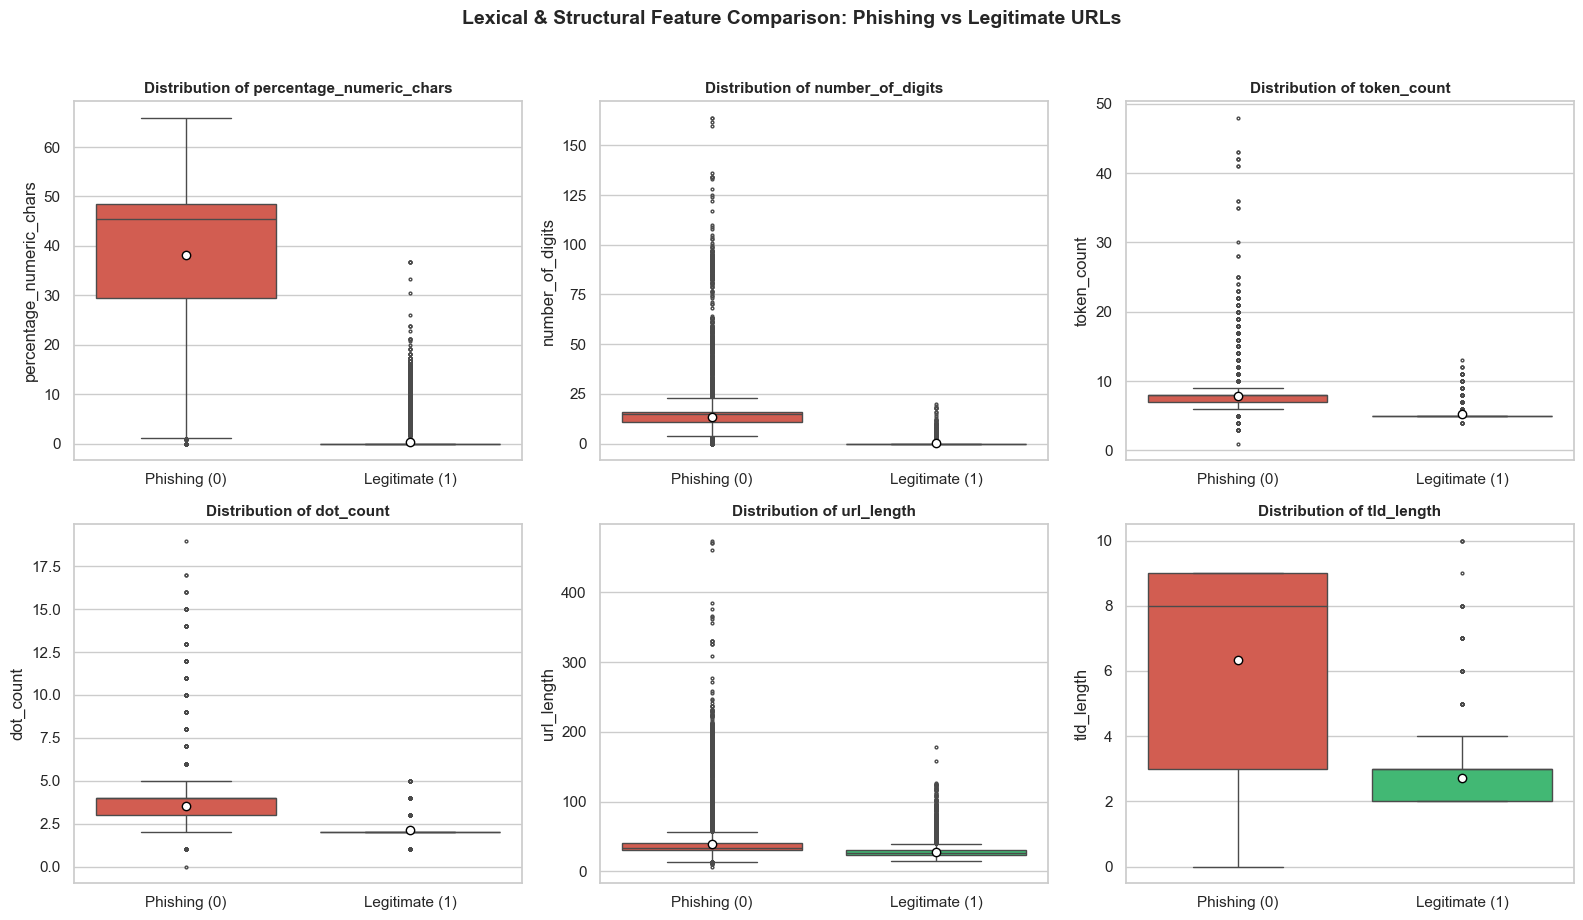

In [7]:
phish_data = df_audit[df_audit['ClassLabel'] == 0]
legit_data = df_audit[df_audit['ClassLabel'] == 1]

tests = []
for col in num_cols:
    p_s = phish_data[col]
    l_s = legit_data[col]
    
    u_stat, p_val = stats.mannwhitneyu(p_s, l_s, alternative='two-sided')
    
    n1, n2 = len(p_s), len(l_s)
    s1, s2 = p_s.std(), l_s.std()
    pooled_s = np.sqrt(((n1 - 1)*(s1**2) + (n2 - 1)*(s2**2)) / (n1 + n2 - 2))
    cohen_d = (p_s.mean() - l_s.mean()) / (pooled_s + 1e-9)
    
    tests.append({
        'Feature': col,
        'Phish_Mean': round(p_s.mean(), 3),
        'Phish_Median': round(p_s.median(), 3),
        'Legit_Mean': round(l_s.mean(), 3),
        'Legit_Median': round(l_s.median(), 3),
        'Cohen_d': round(cohen_d, 3),
        'Abs_Cohen_d': round(abs(cohen_d), 3),
        'p_value': p_val
    })

hypo_df = pd.DataFrame(tests).sort_values(by='Abs_Cohen_d', ascending=False)
print("Hasil Uji Hipotesis Mann-Whitney U dan Effect Size Cohen's d:")
display(hypo_df[['Feature', 'Phish_Mean', 'Phish_Median', 'Legit_Mean', 'Legit_Median', 'Cohen_d', 'p_value']])

# Visualisasi Ranking Cohen's d
plt.figure(figsize=(12, 7))
eff_sorted = hypo_df.sort_values(by='Abs_Cohen_d', ascending=True)
bar_colors = ['#e74c3c' if x > 0 else '#3498db' for x in eff_sorted['Cohen_d']]
bars = plt.barh(eff_sorted['Feature'], eff_sorted['Cohen_d'], color=bar_colors, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title("Feature Discriminative Power (Cohen's d Effect Size)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Cohen's d (>0 Lebih Tinggi di Phishing, <0 Lebih Tinggi di Legitimate)")
for bar in bars:
    w = bar.get_width()
    ha = 'left' if w > 0 else 'right'
    offset = 0.15 if w > 0 else -0.15
    plt.text(w + offset, bar.get_y() + bar.get_height()/2, f'{w:.2f}', va='center', ha=ha, fontsize=10, fontweight='bold')
plt.tight_layout()
plot_file4 = PLOT_DIR / '04_url_effect_size_ranking.png'
plt.savefig(plot_file4, dpi=200, bbox_inches='tight')
plt.show()

# Boxplot Fitur Kunci
top_cols = ['percentage_numeric_chars', 'number_of_digits', 'token_count', 'dot_count', 'url_length', 'tld_length']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, feat in enumerate(top_cols):
    sns.boxplot(data=df_audit, x='Class_Name', y=feat, hue='Class_Name', ax=axes[idx], palette=palette, legend=False, showmeans=True,
                meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black', 'markersize':'6'},
                fliersize=2)
    axes[idx].set_title(f'Distribution of {feat}', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('')
plt.suptitle('Lexical & Structural Feature Comparison: Phishing vs Legitimate URLs', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plot_file2 = PLOT_DIR / '02_url_top_features_comparison.png'
plt.savefig(plot_file2, dpi=200, bbox_inches='tight')
plt.show()


## 1.9 Multicollinearity & Feature Correlation Analysis

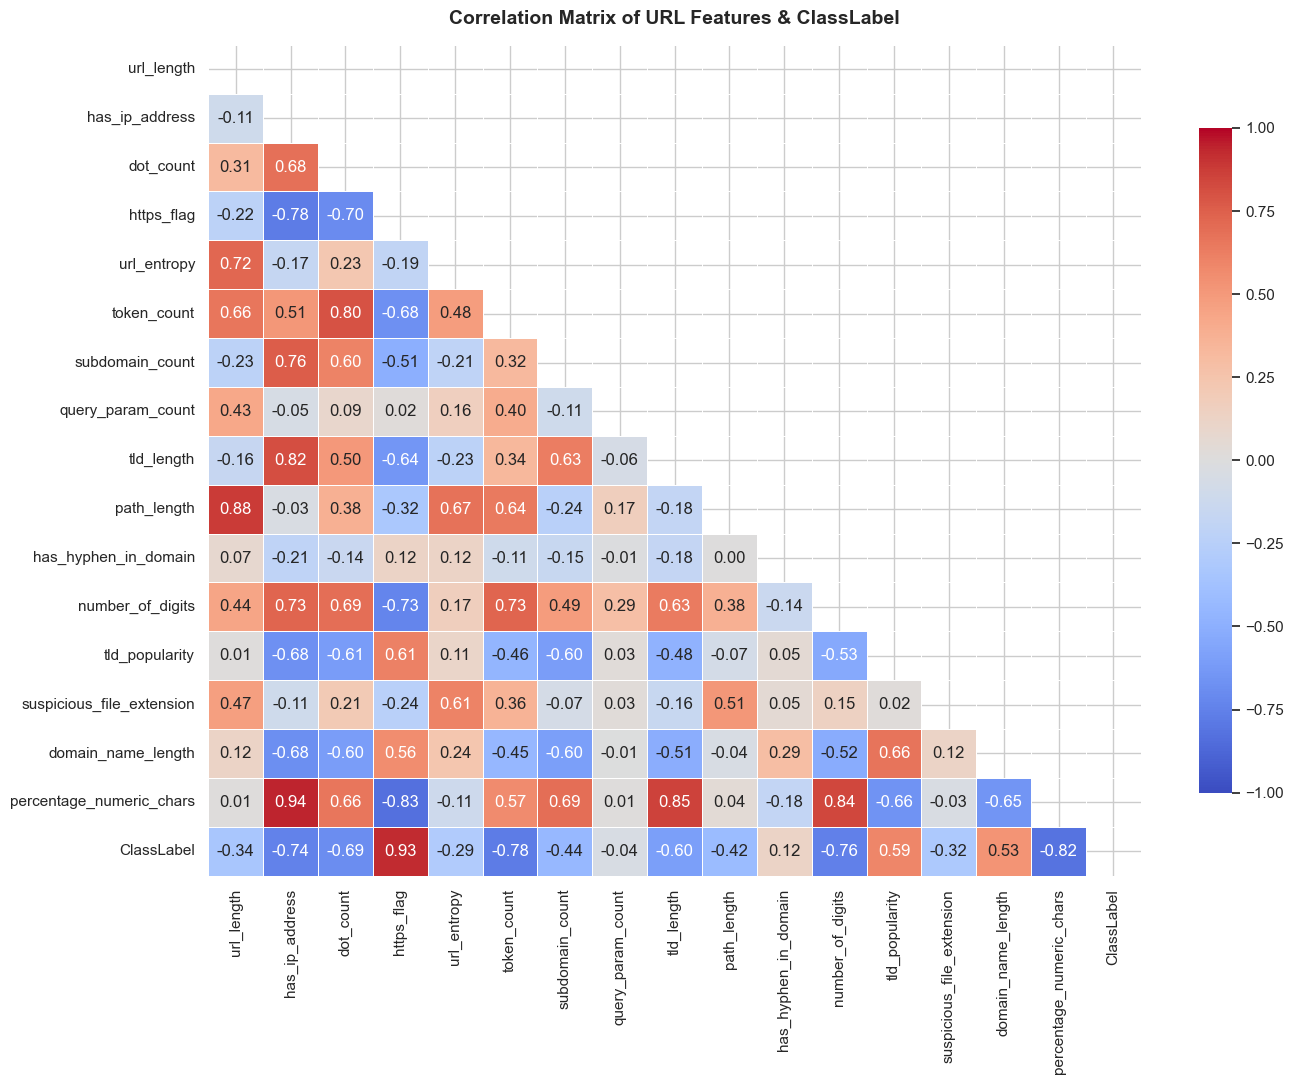

Pasangan Fitur dengan Multikolinearitas Tinggi (|r| >= 0.70):


,Feature 1,Feature 2,Correlation
0,url_length,url_entropy,0.720
1,url_length,path_length,0.879
2,has_ip_address,https_flag,-0.777
3,has_ip_address,subdomain_count,0.758
4,has_ip_address,tld_length,0.819
5,has_ip_address,number_of_digits,0.730
6,has_ip_address,percentage_numeric_chars,0.942
7,dot_count,token_count,0.798
8,https_flag,number_of_digits,-0.727
9,https_flag,percentage_numeric_chars,-0.834


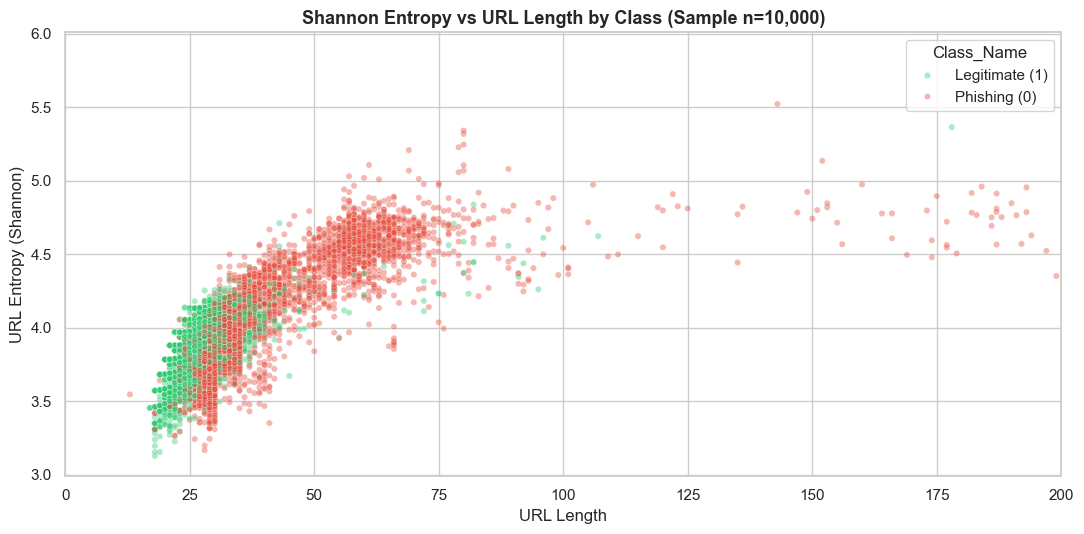

In [8]:
corr = df_audit[num_cols + ['ClassLabel']].corr()

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix of URL Features & ClassLabel', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plot_file3 = PLOT_DIR / '03_url_correlation_matrix.png'
plt.savefig(plot_file3, dpi=200, bbox_inches='tight')
plt.show()

high_corr = []
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        c1, c2 = corr.columns[i], corr.columns[j]
        val = corr.iloc[i, j]
        if abs(val) >= 0.70 and c1 != 'ClassLabel' and c2 != 'ClassLabel':
            high_corr.append({'Feature 1': c1, 'Feature 2': c2, 'Correlation': round(val, 3)})

print("Pasangan Fitur dengan Multikolinearitas Tinggi (|r| >= 0.70):")
display(pd.DataFrame(high_corr))

# Scatter URL Entropy vs Length
plt.figure(figsize=(11, 5.5))
sample_plot = df_audit.sample(10000, random_state=42)
sns.scatterplot(data=sample_plot, x='url_length', y='url_entropy', hue='Class_Name', palette=palette, alpha=0.4, s=20)
plt.title('Shannon Entropy vs URL Length by Class (Sample n=10,000)', fontsize=13, fontweight='bold')
plt.xlabel('URL Length')
plt.ylabel('URL Entropy (Shannon)')
plt.xlim(0, 200)
plt.tight_layout()
plot_file5 = PLOT_DIR / '05_url_entropy_vs_length.png'
plt.savefig(plot_file5, dpi=200, bbox_inches='tight')
plt.show()


## 1.10 Threat Validity & Data Source Bias Audit

Temuan Bias Sumber Data:
1. Bias Protokol HTTPS (https_flag):
   * Pada kelas legitimate, 100% URL menggunakan HTTPS.
   * Pada kelas phishing, hanya 5.5% yang menggunakan HTTPS.
   * Evaluasi Risiko: Penyerang phishing modern saat ini telah mengadopsi sertifikat SSL/TLS gratis secara luas. Mengandalkan https_flag secara berlebihan dapat menghasilkan false negatives pada URL phishing modern.
2. Dominasi Pola Domain Tertentu:
   * URL legitimate bersumber dari platform seperti Stack Overflow dan Wikipedia dengan struktur path dan domain yang seragam.


## 1.11 Audit Summary & Handoff ke Cleanroom Preprocessing

Ringkasan Hasil Audit (Keputusan: fix-first):
* Missing Values: 1 baris NaN pada ClassLabel.
* Duplikasi: 346 baris duplikat persis.
* Sentinel Values: 1.308 baris dengan subdomain_count == -1.
* Artefak Crawler: 1 baris URL bernilai "Offline".
* Polarisasi Label: 0.0 = Phishing, 1.0 = Legitimate (akan distandardisasi pada Chapter 2).


# CHAPTER 2 : Data Cleaning & Preprocessing

Pada bab ini, kita mengeksekusi pipeline *data cleanroom* secara sistematis dan terdokumentasi untuk membersihkan anomali yang ditemukan pada Chapter 1:
1. **Eliminasi Missing Value:** Menghapus baris dengan nilai `ClassLabel` kosong (`NaN`).
2. **Pembersihan Artefak Crawler:** Menghapus entri teks non-URL seperti `"Offline"`.
3. **Deduplikasi Baris:** Menghapus baris duplikat identik untuk mencegah kebocoran informasi (*data leakage*).
4. **Normalisasi Nilai Sentinel:** Menangani nilai `subdomain_count == -1` dengan membatasi nilai minimum logis ($0$).
5. **Standardisasi Label Target:** Melakukan re-mapping label biner menjadi `is_phishing` (di mana $1 = \text{Phishing}$ dan $0 = \text{Legitimate}$) agar selaras dengan standar deteksi ancaman.
6. **Validasi Integritas Pasca-Pembersihan:** Memverifikasi integritas dataset bersih dengan perbandingan sebelum vs sesudah.
7. **Penyimpanan Data Bersih:** Mengekspor hasil pembersihan ke direktori `data/url/processed/url_features_cleaned.csv`.
8. **Pembagian Data Bebas Leakage (Train-Test Split):** Melakukan stratified train-test split ($80:20$) dengan `random_state=42` sesuai panduan scikit-learn.


## 2.1 Eksekusi Pipeline Data Cleanroom

In [9]:
# Inisialisasi pelacakan jumlah baris
audit_tracker = []
audit_tracker.append({'Tahap': '1. Dataset Mentah (Raw Ingestion)', 'Jumlah Baris': len(df_raw), 'Baris Dihapus': 0})

# 1. Hapus missing value pada ClassLabel
df_clean = df_raw.dropna(subset=['ClassLabel']).copy()
rows_dropped_null = len(df_raw) - len(df_clean)
audit_tracker.append({'Tahap': '2. Eliminasi Missing ClassLabel (NaN)', 'Jumlah Baris': len(df_clean), 'Baris Dihapus': rows_dropped_null})

# 2. Hapus artefak teks crawler non-URL ('offline')
df_clean = df_clean[df_clean['URL'].str.lower() != 'offline'].copy()
rows_dropped_artifact = len(df_raw) - rows_dropped_null - len(df_clean)
audit_tracker.append({'Tahap': '3. Eliminasi Artefak Non-URL (String Offline)', 'Jumlah Baris': len(df_clean), 'Baris Dihapus': rows_dropped_artifact})

# 3. Deduplikasi baris persis
n_before_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
rows_dropped_dedup = n_before_dedup - len(df_clean)
audit_tracker.append({'Tahap': '4. Eliminasi Baris Duplikat Identik', 'Jumlah Baris': len(df_clean), 'Baris Dihapus': rows_dropped_dedup})

# 4. Normalisasi nilai sentinel subdomain_count (-1 -> 0)
sentinel_count_before = (df_clean['subdomain_count'] < 0).sum()
df_clean['subdomain_count'] = df_clean['subdomain_count'].clip(lower=0)
sentinel_count_after = (df_clean['subdomain_count'] < 0).sum()
print(f"Normalisasi Sentinel subdomain_count: {sentinel_count_before:,} baris dinormalisasi ke 0.")

# 5. Standardisasi label target: 1 = Phishing, 0 = Legitimate
# Nilai awal: 0.0 = Phishing, 1.0 = Legitimate
df_clean['is_phishing'] = (df_clean['ClassLabel'] == 0.0).astype(int)
df_clean = df_clean.drop(columns=['ClassLabel'])

# Tampilkan log ringkasan tahapan pembersihan
tracker_df = pd.DataFrame(audit_tracker)
tracker_df['Total Berkurang Kumulatif'] = len(df_raw) - tracker_df['Jumlah Baris']
print("\nLog Eksekusi Cleanroom Data URL:")
display(tracker_df)


Normalisasi Sentinel subdomain_count: 1,307 baris dinormalisasi ke 0.

Log Eksekusi Cleanroom Data URL:


,Tahap,Jumlah Baris,Baris Dihapus,Total Berkurang Kumulatif
0,1. Dataset Mentah (Raw Ingestion),101219,0,0
1,2. Eliminasi Missing ClassLabel (NaN),101218,1,1
2,3. Eliminasi Artefak Non-URL (String Offline),101217,1,2
3,4. Eliminasi Baris Duplikat Identik,100871,346,348


## 2.2 Validasi Integritas Pasca-Pembersihan

Memverifikasi bahwa dataset hasil pembersihan telah bebas dari missing value, duplikasi, dan nilai sentinel negatif.


In [10]:
validation_metrics = {
    'Metrik Kualitas': [
        'Total Sampel Valid',
        'Total Kolom',
        'Jumlah Missing Values (Semua Kolom)',
        'Jumlah Duplikasi Baris',
        'Nilai Minimum subdomain_count',
        'Sampel Kelas Phishing (Label 1)',
        'Sampel Kelas Legitimate (Label 0)',
        'Persentase Phishing (%)',
        'Persentase Legitimate (%)'
    ],
    'Sebelum Pembersihan (Raw)': [
        f"{len(df_raw):,}",
        f"{df_raw.shape[1]}",
        f"{df_raw.isnull().sum().sum():,}",
        f"{df_raw.duplicated().sum():,}",
        f"{df_raw['subdomain_count'].min()}",
        f"{(df_raw['ClassLabel'] == 0.0).sum():,}",
        f"{(df_raw['ClassLabel'] == 1.0).sum():,}",
        f"{(df_raw['ClassLabel'] == 0.0).mean()*100:.2f}%",
        f"{(df_raw['ClassLabel'] == 1.0).mean()*100:.2f}%"
    ],
    'Sesudah Pembersihan (Clean)': [
        f"{len(df_clean):,}",
        f"{df_clean.shape[1]}",
        f"{df_clean.isnull().sum().sum():,}",
        f"{df_clean.duplicated().sum():,}",
        f"{df_clean['subdomain_count'].min()}",
        f"{(df_clean['is_phishing'] == 1).sum():,}",
        f"{(df_clean['is_phishing'] == 0).sum():,}",
        f"{(df_clean['is_phishing'] == 1).mean()*100:.2f}%",
        f"{(df_clean['is_phishing'] == 0).mean()*100:.2f}%"
    ]
}

val_df = pd.DataFrame(validation_metrics)
print("Tabel Komparasi Kualitas Data Sebelum vs Sesudah Pembersihan:")
display(val_df)


Tabel Komparasi Kualitas Data Sebelum vs Sesudah Pembersihan:


,Metrik Kualitas,Sebelum Pembersihan (Raw),Sesudah Pembersihan (Clean)
0,Total Sampel Valid,"101,219","100,871"
1,Total Kolom,18,18
2,Jumlah Missing Values (Semua Kolom),1,0
3,Jumlah Duplikasi Baris,346,0
4,Nilai Minimum subdomain_count,-1,0
5,Sampel Kelas Phishing (Label 1),"63,678","63,491"
6,Sampel Kelas Legitimate (Label 0),"37,540","37,380"
7,Persentase Phishing (%),62.91%,62.94%
8,Persentase Legitimate (%),37.09%,37.06%


## 2.3 Penyimpanan Dataset Bersih (Processed Data)

In [11]:
OUTPUT_CLEAN_DIR = Path('data/url/processed')
OUTPUT_CLEAN_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_FILE_PATH = OUTPUT_CLEAN_DIR / 'url_features_cleaned.csv'
df_clean.to_csv(CLEAN_FILE_PATH, index=False)

print(f"Dataset bersih berhasil disimpan ke: {CLEAN_FILE_PATH}")
print(f"Ukuran file: {CLEAN_FILE_PATH.stat().st_size / (1024 ** 2):.2f} MB")
print(f"Dimensi akhir: {df_clean.shape[0]:,} baris x {df_clean.shape[1]} kolom")


Dataset bersih berhasil disimpan ke: data\url\processed\url_features_cleaned.csv
Ukuran file: 8.59 MB
Dimensi akhir: 100,871 baris x 18 kolom


## 2.4 Pembagian Data Bebas Kebocoran (Train-Test Split) (/scikit-learn)

Sesuai metodologi `/scikit-learn`:
* Pemisahan fitur prediktor $X$ dan target $y$. Kolom identitas `URL` mentah dikeluarkan dari matriks fitur tabular.
* Pembagian data menggunakan `train_test_split` dengan rasio $80\%$ training set dan $20\%$ testing set.
* Parameter `stratify=y` digunakan untuk menjaga proporsi kelas $62,94\% : 37,06\%$ tetap konsisten di kedua subset.
* Parameter `random_state=42` ditetapkan untuk menjamin reproduktibilitas penuh.


In [12]:
from sklearn.model_selection import train_test_split

# Pisahkan matriks fitur X dan target y
feature_cols = [c for c in df_clean.columns if c not in ['URL', 'is_phishing']]
X = df_clean[feature_cols]
y = df_clean['is_phishing']

print(f"Jumlah Fitur Prediktor Tabular: {len(feature_cols)}")
print("Daftar Fitur:", feature_cols)

# Stratified Split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

split_summary = pd.DataFrame({
    'Subset': ['Training Set (80%)', 'Testing Set (20%)', 'Total Data'],
    'Total Sampel': [len(X_train), len(X_test), len(X)],
    'Sampel Phishing (1)': [sum(y_train == 1), sum(y_test == 1), sum(y == 1)],
    'Sampel Legitimate (0)': [sum(y_train == 0), sum(y_test == 0), sum(y == 0)],
    'Proporsi Phishing (%)': [
        f"{sum(y_train == 1)/len(y_train)*100:.2f}%",
        f"{sum(y_test == 1)/len(y_test)*100:.2f}%",
        f"{sum(y == 1)/len(y)*100:.2f}%"
    ]
})

print("\nRingkasan Pembagian Data (Train-Test Split):")
display(split_summary)


Jumlah Fitur Prediktor Tabular: 16
Daftar Fitur: ['url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars']



Ringkasan Pembagian Data (Train-Test Split):


,Subset,Total Sampel,Sampel Phishing (1),Sampel Legitimate (0),Proporsi Phishing (%)
0,Training Set (80%),80696,50792,29904,62.94%
1,Testing Set (20%),20175,12699,7476,62.94%
2,Total Data,100871,63491,37380,62.94%


## 2.5 Handoff ke Chapter 3 (Model Training & Evaluation)

Dataset telah berada dalam kondisi siap latih (*model-ready*):
* `X_train` dan `y_train` siap digunakan untuk pelatihan baseline Random Forest dan tuning XGBoost Classifier.
* `X_test` dan `y_test` dikunci secara terisolasi untuk evaluasi final tanpa risiko kebocoran (*data leakage*).
* Fitur tabular tidak memiliki nilai missing maupun tak hingga.
